In [3]:
#! ai aided cell to help me fix some import path issues I didnt understand
import sys
from pathlib import Path

root = Path.cwd()
if root.name == "src":
    root = root.parent

if not (root / "src" / "model.py").is_file():
    raise RuntimeError(f"Not at the repository root: {root}")

if str(root) not in sys.path:
    sys.path.insert(0, str(root))

In [4]:
import torch
from src.model import ViT
from src.train import Checkpoint, load_checkpoint
from src.dataset import TODataset, Mode
from pathlib import Path
from src.utils import visualize, reshape_distribution

In [5]:
# load data
dataset = TODataset(mode=Mode.TEST)

INFO:src.dataset:Initializing Dataset with mode test
INFO:src.dataset:Dataset: n_samples 2012
INFO:src.dataset:Dataset initialized succesfully


In [11]:
# load model

path = Path.cwd() / "../models/ViT_1070424_4_2_1_2/adam_0.001_bce/epoch_10000.pth"
checkpoint: Checkpoint = load_checkpoint(path)
model_state_dict = checkpoint.model_state_dict
model = ViT(
    embedding_dims=checkpoint.params.embedding_dims,
    query_dims=checkpoint.params.query_dims,
    n_attention_blocks=checkpoint.params.n_attention_blocks,
    n_attention_heads=checkpoint.params.n_attention_heads,
)
model.load_state_dict(checkpoint.model_state_dict)
model.eval()  # set the model to evaluation mode

INFO:root:Loading checkpoint from c:\Users\lucas\Desktop\Uni\Lernen\Master\5. Semester\Applied Deep Learning\12435611_topology-optimization\src\..\models\ViT_1070424_4_2_1_2\adam_0.001_bce\epoch_10000.pth


ViT(
  (linear_patch): Linear(in_features=64, out_features=4, bias=True)
  (linear_param): Linear(in_features=261, out_features=4, bias=True)
  (readout): Linear(in_features=260, out_features=4096, bias=True)
  (linear_vs): ModuleList(
    (0): Linear(in_features=4, out_features=4, bias=True)
  )
  (linear_qs): ModuleList(
    (0): Linear(in_features=4, out_features=2, bias=True)
  )
  (linear_ks): ModuleList(
    (0): Linear(in_features=4, out_features=2, bias=True)
  )
  (linears): ModuleList(
    (0): Linear(in_features=4, out_features=4, bias=True)
  )
)

True density shape: torch.Size([4096])
Predicted density shape: torch.Size([4096])
Stress shape: torch.Size([4096])


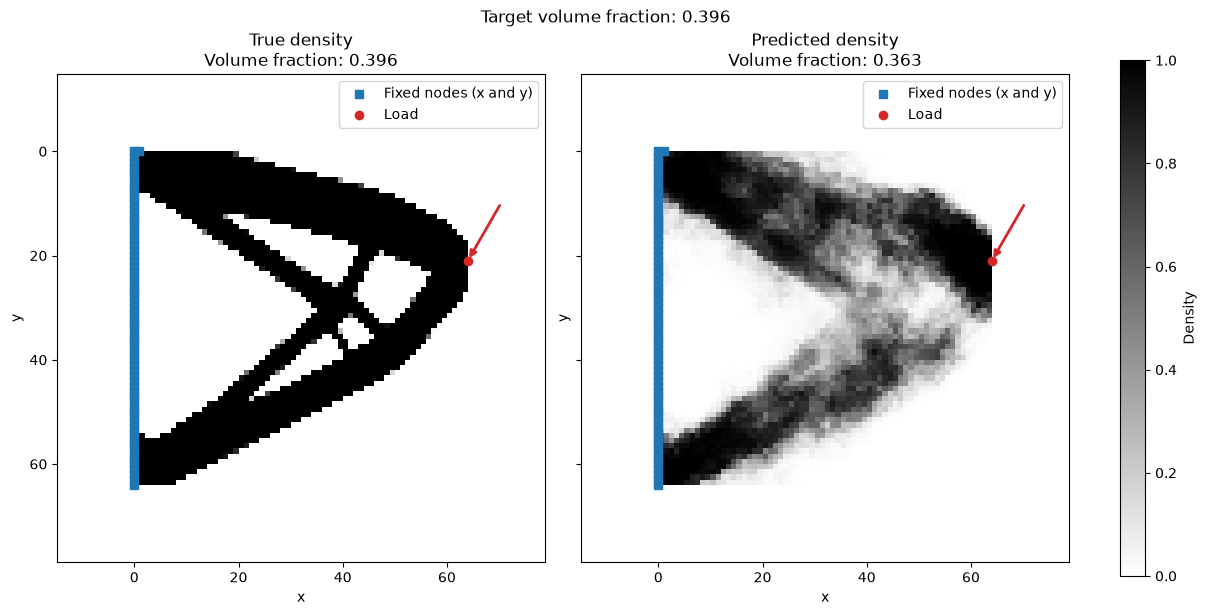

(<Figure size 1200x600 with 3 Axes>,
 array([<Axes: title={'center': 'True density\nVolume fraction: 0.396'}, xlabel='x', ylabel='y'>,
        <Axes: title={'center': 'Predicted density\nVolume fraction: 0.363'}, xlabel='x', ylabel='y'>],
       dtype=object))

In [14]:
sample_idx = 106 # 101 # 100 # 11 # 92 # 
# todo: check 103 -> data
sample = dataset[sample_idx]
volume_fraction = sample[0][0]
load = sample[0][1:5]
bcs = sample[0][5:5+4*64]
stress = sample[0][5+4*64:]

true_density = sample[1]
predicted_density = model(sample[0].unsqueeze(0)).squeeze(0)

# round to 1 or 0
# predicted_density = (predicted_density > 0.5).float()

print("True density shape:", true_density.shape)
print("Predicted density shape:", predicted_density.shape)
print("Stress shape:", stress.shape)

stress = stress
true_density = true_density
with torch.no_grad():
    predicted_density = predicted_density
    
    
visualize(
    true_density,
    predicted_density,
    load=load,
    bcs=bcs,
    volume_fraction=volume_fraction
)



In [48]:
with torch.no_grad():
    p = model(sample[0].unsqueeze(0))[0]
    logits = torch.logit(p.clamp(1e-6, 1 - 1e-6))
    stray = (p > 0.95) & (sample[1] < 0.05)
    print("stray pixels:", stray.sum().item(),
          "| logits min/median:", logits[stray].min().item(), logits[stray].median().item())

stray pixels: 85 | logits min/median: 2.9775161743164062 4.077902317047119
